# Bike Sharing: Should We Buy More Bikes?
**Question from the CEO:** riders can't find bikes, yet bikes sit unused. Do we buy more?

**Data:** UCI Bike Sharing (Capital Bikeshare, Washington DC, 2011-2012), `hour.csv` as the single source of truth.

**What this data cannot tell us (stated up front):**
1. It has **completed rentals only** (`cnt`). A rider who found no bike is never recorded, so true demand is higher than what we see.
2. It is **city-wide**. No stations, no bike inventory, no fleet size. So it cannot show *where* bikes are missing.
3. Only **two years**, with strong growth from 2011 to 2012.

So the notebook can show *when* pressure is concentrated and size a *lower-bound* fleet under stated assumptions. It cannot prove why riders fail to find bikes.

## Decision log
| # | Decision | Alternative | Why |
|---|---|---|---|
| 1 | Use `hour.csv` only; `day.csv` for a reconciliation check | Model on `day.csv` | Daily totals hide the commuter peaks the hypothesis depends on |
| 2 | Keep missing hours, no imputation of rentals; zero-fill only for profile averages | Drop or interpolate | Missing rows look like hours with no rentals (to verify below) |
| 3 | Time-based split: train before 2012-07-01, test 2012-07-01 to 2012-12-31 | Random split | A random split lets the model see the future |
| 4 | Do not use `casual` / `registered` as inputs | Use them | They sum to the target (leakage) |
| 5 | Poisson-type models | Plain linear regression | Counts, non-negative, variance grows with the mean |
| 6 | Fleet need = percentile of hourly demand x trip minutes / 60 | Read fleet from data | No fleet size in the data. Trip length and percentile are assumptions, so we show a sensitivity table |
| 8 | Boosting uses `yr` (0/1) rather than a day counter as its growth feature | `t_days` | In the diagnostic below, `t_days` gave the largest peak under-prediction. Caveat: chosen after looking at test results, so test scores are slightly optimistic |
| 7 | Weather columns are used as recorded (assumes a good forecast) | Lagged "nowcast" model | Planning happens ahead of time; real forecast error is not modelled |

## 1. Load and quality checks

In [1]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, seaborn as sns
from scipy import stats
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.linear_model import PoissonRegressor
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
sns.set_theme(style="whitegrid"); pd.set_option("display.width", 140)
SEED = 42

# ---- Assumptions (change here, everything below updates) ----
TEST_START   = "2012-07-01"   # train < this date, test >= this date
PCTL         = 0.90           # service level: enough bikes in 90% of hours
TRIP_MIN     = 20             # assumed average trip length in minutes (NOT in the data)

hour = pd.read_csv("hour.csv", parse_dates=["dteday"])
day  = pd.read_csv("day.csv",  parse_dates=["dteday"])
print(hour.shape, day.shape)
hour.head()

(17379, 17) (731, 16)


,instant,dteday,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
0,1,2011-01-01,1,0,1,0,0,6,0,1,0.24,0.2879,0.81,0.0,3,13,16
1,2,2011-01-01,1,0,1,1,0,6,0,1,0.22,0.2727,0.80,0.0,8,32,40
2,3,2011-01-01,1,0,1,2,0,6,0,1,0.22,0.2727,0.80,0.0,5,27,32
3,4,2011-01-01,1,0,1,3,0,6,0,1,0.24,0.2879,0.75,0.0,3,10,13
4,5,2011-01-01,1,0,1,4,0,6,0,1,0.24,0.2879,0.75,0.0,0,1,1


In [2]:
# 1a. Basic integrity
print("nulls:", int(hour.isna().sum().sum()), "| duplicate rows:", int(hour.duplicated().sum()),
      "| duplicate (date,hr):", int(hour.duplicated(["dteday","hr"]).sum()))
print("casual + registered == cnt everywhere:", bool((hour.casual + hour.registered == hour.cnt).all()))
print("date range:", hour.dteday.min().date(), "to", hour.dteday.max().date())

# 1b. Value-range and consistency checks
print("hr in 0..23:", hour.hr.between(0,23).all())
print("weekday matches date:", bool(((hour.dteday.dt.dayofweek + 1) % 7 == hour.weekday).all()))
print("mnth matches date:", bool((hour.dteday.dt.month == hour.mnth).all()),
      "| yr matches date:", bool((hour.dteday.dt.year - 2011 == hour.yr).all()))
wd_expected = ((hour.weekday.between(1,5)) & (hour.holiday == 0)).astype(int)
print("workingday == weekday(1-5) & not holiday:", bool((wd_expected == hour.workingday).all()))
print("normalised columns within [0,1]:", bool(hour[["temp","atemp","hum","windspeed"]].apply(lambda s: s.between(0,1)).all().all()))
print("humidity == 0 rows:", int((hour.hum == 0).sum()), "on dates:", sorted(hour.loc[hour.hum==0,"dteday"].dt.date.astype(str).unique()), "(looks like a missing-value placeholder; kept as is, a single day)")

nulls: 0 | duplicate rows: 0 | duplicate (date,hr): 0
casual + registered == cnt everywhere: True
date range: 2011-01-01 to 2012-12-31
hr in 0..23: True
weekday matches date: True
mnth matches date: True | yr matches date: True
workingday == weekday(1-5) & not holiday: True
normalised columns within [0,1]: True
humidity == 0 rows: 22 on dates: ['2011-03-10'] (looks like a missing-value placeholder; kept as is, a single day)


In [3]:
# 1c. Missing hours: 2 years x 24h = 17,544 expected, we have 17,379
full_idx = pd.date_range("2011-01-01 00:00", "2012-12-31 23:00", freq="h")
hour["ts"] = hour.dteday + pd.to_timedelta(hour.hr, unit="h")
missing = full_idx.difference(hour.ts)
print("expected:", len(full_idx), "| present:", len(hour), "| missing:", len(missing))
print("\nMissing hours by hour-of-day:")
print(pd.Series(missing.hour).value_counts().sort_index().to_string())

expected: 17544 | present: 17379 | missing: 165

Missing hours by hour-of-day:
0      5
1      7
2     16
3     34
4     34
5     14
6      6
7      4
8      4
9      4
10     4
11     4
12     3
13     2
14     2
15     2
16     1
17     1
18     3
19     3
20     3
21     3
22     3
23     3


In [4]:
# Are missing hours really "zero rentals"? Compare: demand in the hours right next to a gap.
cnt_by_ts = hour.set_index("ts").cnt
neigh = []
for t in missing:
    for dt in (-1, 1):
        n = t + pd.Timedelta(hours=dt)
        if n in cnt_by_ts.index: neigh.append(cnt_by_ts[n])
print("median rentals in hours adjacent to a gap:", np.median(neigh), "| overall median:", hour.cnt.median())

# Days with unusually few recorded hours (possible real events, e.g. Hurricane Sandy Oct 2012)
per_day = hour.groupby("dteday").size()
short = per_day[per_day < 20]
print("\nDays with < 20 recorded hours:", len(short))
print(short.to_string())

median rentals in hours adjacent to a gap: 3.0 | overall median: 142.0

Days with < 20 recorded hours: 8
dteday
2011-01-18    12
2011-01-26    16
2011-01-27     8
2011-02-22    18
2011-08-27    18
2011-08-28    17
2012-10-29     1
2012-10-30    11


**Reading this:** the missing rows sit mostly in the small hours (check the table above), and the hours next to them have very low rentals. That supports reading a missing row as "no rentals that hour". This is an **inference, not a fact** in the file. Days with very few rows are flagged, not fixed, because some are real events (storms), not data errors.

In [5]:
# 1d. Outliers: use IQR within each hour-of-day x workingday (a global IQR would flag every rush hour)
g = hour.groupby(["hr","workingday"]).cnt
q1, q3 = g.transform(lambda s: s.quantile(.25)), g.transform(lambda s: s.quantile(.75))
hour["is_outlier"] = hour.cnt > (q3 + 1.5*(q3-q1))
print("flagged high outliers:", int(hour.is_outlier.sum()), f"({hour.is_outlier.mean():.1%})")
print(hour.loc[hour.is_outlier].groupby("hr").size().to_string())
print("\nlargest hours:"); print(hour.nlargest(5,"cnt")[["dteday","hr","weekday","workingday","weathersit","temp","cnt"]])

flagged high outliers: 130 (0.7%)
hr
0     16
1     18
2      9
3     33
4      9
5      5
6      5
7      6
8      4
12     2
14     5
15     5
20     1
21     2
22     5
23     5

largest hours:
          dteday  hr  weekday  workingday  weathersit  temp  cnt
14773 2012-09-12  18        3           1           1  0.66  977
14964 2012-09-20  17        4           1           1  0.64  976
14748 2012-09-11  17        2           1           1  0.70  970
14725 2012-09-10  18        1           1           1  0.62  968
15084 2012-09-25  17        2           1           1  0.66  967


**Decision:** outliers are **kept**. High values at rush hours in good weather are genuine busy hours, and those are exactly the hours that drive fleet need. Removing them would understate the answer.

In [6]:
# 1e. Cross-check with day.csv (reconciliation only. NOT used for modelling or the fleet estimate)
agg = hour.groupby("dteday")[["casual","registered","cnt"]].sum().reset_index()
chk = day[["dteday","casual","registered","cnt"]].merge(agg, on="dteday", suffixes=("_day","_hour"), how="outer", indicator=True)
print("days only in one file:", int((chk._merge != "both").sum()))
for c in ["casual","registered","cnt"]:
    d = (chk[f"{c}_day"] - chk[f"{c}_hour"]).abs()
    print(f"{c}: days with mismatch = {int((d>0).sum())}, max diff = {d.max()}")

w = hour.groupby("dteday")[["temp","hum","windspeed"]].mean().reset_index()
wc = day[["dteday","temp","hum","windspeed"]].merge(w, on="dteday", suffixes=("_day","_hour"))
for c in ["temp","hum","windspeed"]:
    print(f"{c}: mean |daily - mean of hourly| = {(wc[c+'_day']-wc[c+'_hour']).abs().mean():.4f}")

days only in one file: 0
casual: days with mismatch = 0, max diff = 0
registered: days with mismatch = 0, max diff = 0
cnt: days with mismatch = 0, max diff = 0


temp: mean |daily - mean of hourly| = 0.0000
hum: mean |daily - mean of hourly| = 0.0000
windspeed: mean |daily - mean of hourly| = 0.0000


**Reading this:** daily rental totals match the hourly file exactly, so the missing hours carry zero rentals (otherwise the daily totals would be larger than the hourly sums). That upgrades the earlier inference. Daily weather equals the mean of the hourly values (difference shows as 0.0000 at 4 decimals), so the daily file was built from the same hourly data. That is why `day.csv` adds no new information. `day.csv` is **not** used further: it hides the within-day peaks the hypothesis is about.

## 2. Features

In [7]:
df = hour.copy()
# un-normalise weather for readability (UCI documentation: temp/41, atemp/50, hum/100, windspeed/67)
df["temp_c"]  = df.temp  * 41
df["atemp_c"] = df.atemp * 50
df["hum_pct"] = df.hum   * 100
df["wind_kmh"] = df.windspeed * 67

df["is_workday"] = df.workingday
df["rush_am"] = df.hr.between(7, 9).astype(int)
df["rush_pm"] = df.hr.between(17, 19).astype(int)
df["is_rush"] = ((df.rush_am | df.rush_pm) & (df.is_workday == 1)).astype(int)
df["hr_wd"]   = df.hr + 24 * df.is_workday            # hour-of-day shape differs a lot by day type
df["t_days"]  = (df.dteday - df.dteday.min()).dt.days  # linear growth trend
df["hr_sin"], df["hr_cos"] = np.sin(2*np.pi*df.hr/24), np.cos(2*np.pi*df.hr/24)
df["rain_snow"] = (df.weathersit >= 3).astype(int)
df[["dteday","hr","is_rush","hr_wd","t_days","temp_c","hum_pct","wind_kmh","cnt"]].head()

,dteday,hr,is_rush,hr_wd,t_days,temp_c,hum_pct,wind_kmh,cnt
0,2011-01-01,0,0,0,0,9.84,81.0,0.0,16
1,2011-01-01,1,0,1,0,9.02,80.0,0.0,40
2,2011-01-01,2,0,2,0,9.02,80.0,0.0,32
3,2011-01-01,3,0,3,0,9.84,75.0,0.0,13
4,2011-01-01,4,0,4,0,9.84,75.0,0.0,1


| Feature | Why it is there |
|---|---|
| `hr`, `weekday`, `workingday`, `holiday` | daily and weekly cycles |
| `hr_wd` (hour x day type) | the 24-hour shape is completely different on working days and weekends |
| `is_rush` | 7-9am and 5-7pm on working days, the hypothesis window |
| `t_days` (GLM) / `yr` (boosting) | 2012 is much busier than 2011. The GLM takes a linear trend. For boosting a continuous trend turned out worse (diagnostic in section 5) |
| `temp_c`, `hum_pct`, `wind_kmh`, `weathersit` | weather effects |
| `mnth` | yearly cycle (only two years observed, so confounded with the trend) |
| *Not used:* `casual`, `registered`, `instant`, `dteday`, `atemp` | leakage / identifier / near-duplicate of `temp` |

## 3. Exploratory analysis

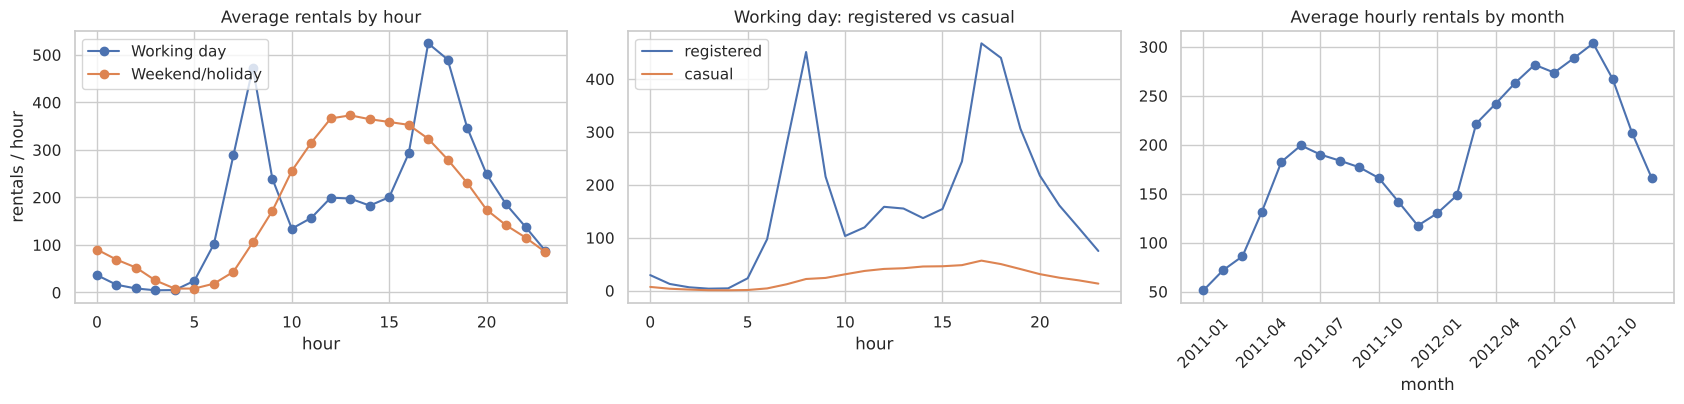

In [8]:
# Zero-filled hourly table so averages include the empty hours
full = pd.DataFrame({"ts": full_idx}).merge(hour[["ts","cnt","casual","registered","workingday"]], on="ts", how="left")
full[["cnt","casual","registered"]] = full[["cnt","casual","registered"]].fillna(0)
full["date"] = full.ts.dt.normalize(); full["hr"] = full.ts.dt.hour; full["yr"] = full.ts.dt.year
wd = hour.groupby("dteday").workingday.first()
full["workingday"] = full.date.map(wd)

prof = full.groupby(["workingday","hr"])[["cnt","casual","registered"]].mean().reset_index()
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
for k, lab in [(1,"Working day"),(0,"Weekend/holiday")]:
    s = prof[prof.workingday==k]; ax[0].plot(s.hr, s.cnt, marker="o", label=lab)
ax[0].set(title="Average rentals by hour", xlabel="hour", ylabel="rentals / hour"); ax[0].legend()
s = prof[prof.workingday==1]
ax[1].plot(s.hr, s.registered, label="registered"); ax[1].plot(s.hr, s.casual, label="casual")
ax[1].set(title="Working day: registered vs casual", xlabel="hour"); ax[1].legend()
m = full.assign(m=full.ts.dt.to_period("M")).groupby("m").cnt.mean()
ax[2].plot(m.index.astype(str), m.values, marker="o"); ax[2].set_xticks(range(0,24,3))
ax[2].set(title="Average hourly rentals by month", xlabel="month"); ax[2].tick_params(axis="x", rotation=45)
plt.tight_layout(); plt.show()

In [9]:
# Numbers behind the picture
w_ = prof[prof.workingday==1].set_index("hr")
print("Working-day average rentals/hr: 8am = %.0f | 5pm = %.0f | 3am = %.1f | all-day mean = %.0f"
      % (w_.cnt[8], w_.cnt[17], w_.cnt[3], w_.cnt.mean()))
print("Registered share of rentals at 8am/5pm: %.0f%% / %.0f%%  vs  midday (12-14h): %.0f%%"
      % (100*w_.registered[8]/w_.cnt[8], 100*w_.registered[17]/w_.cnt[17],
         100*w_.registered[12:14].sum()/w_.cnt[12:14].sum()))
by_year = full.groupby("yr").cnt.mean()
print("Average hourly rentals: 2011 = %.0f | 2012 = %.0f | growth = %.0f%%"
      % (by_year[2011], by_year[2012], 100*(by_year[2012]/by_year[2011]-1)))

Working-day average rentals/hr: 8am = 473 | 5pm = 524 | 3am = 4.6 | all-day mean = 191
Registered share of rentals at 8am/5pm: 95% / 89%  vs  midday (12-14h): 79%
Average hourly rentals: 2011 = 142 | 2012 = 233 | growth = 64%


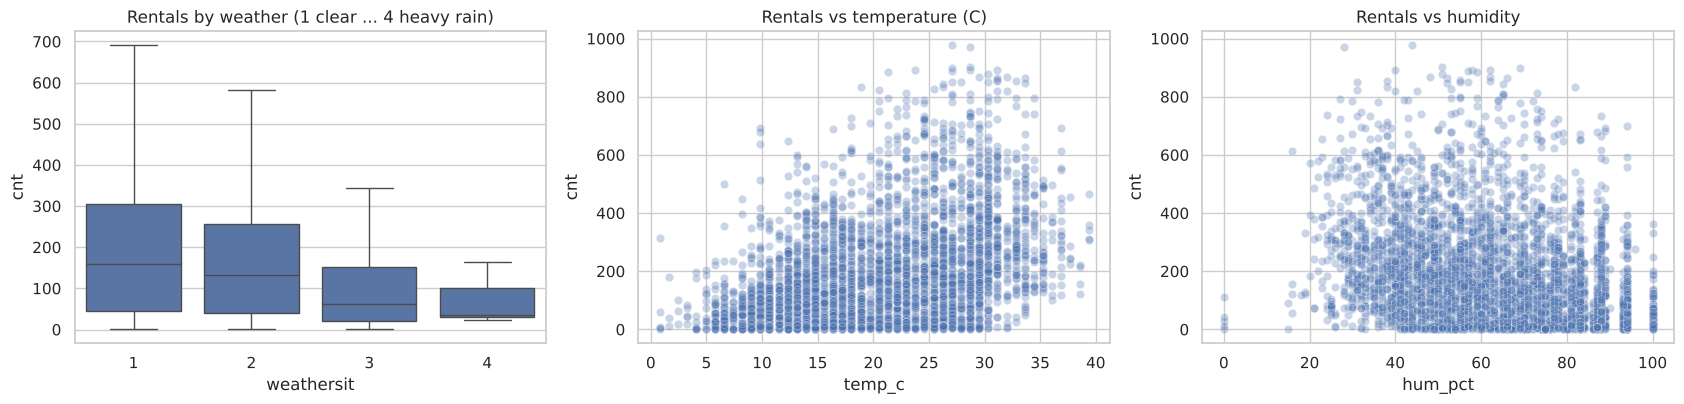

weathersit
1    11413
2     4544
3     1419
4        3


In [10]:
fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
sns.boxplot(data=df, x="weathersit", y="cnt", ax=ax[0], showfliers=False); ax[0].set(title="Rentals by weather (1 clear ... 4 heavy rain)")
sns.scatterplot(data=df.sample(4000, random_state=SEED), x="temp_c", y="cnt", alpha=.3, ax=ax[1]); ax[1].set(title="Rentals vs temperature (C)")
sns.scatterplot(data=df.sample(4000, random_state=SEED), x="hum_pct", y="cnt", alpha=.3, ax=ax[2]); ax[2].set(title="Rentals vs humidity")
plt.tight_layout(); plt.show()
print(df.weathersit.value_counts().sort_index().rename("hours by weathersit").to_string())

**What the EDA shows (see the numbers printed above):**
- Working days have two sharp peaks (about 8am and 5-6pm). Weekends have one broad midday hump.
- The peaks are driven by **registered** riders; casual riders dominate weekend afternoons. This is consistent with commuting, but it is not proof, because there are no trip origins or destinations.
- Demand at 3am is a tiny fraction of demand at the peaks, so the same bikes are mostly idle for much of the day.
- Rentals fall with bad weather and cold, and grow strongly from 2011 to 2012.
- `weathersit = 4` (heavy rain) is almost never observed, so the model knows little about it.

## 4. Hypothesis (design only, this data cannot run it)

**H1:** On working days during 7-9am and 5-7pm, proactively moving bikes to high-demand zones before the peak **reduces the failed-rental rate** compared with the current process.
**H0:** no difference.

**Why it is not testable here:** no treatment (nobody rebalanced differently), no outcome (failed rentals are not recorded), no location. Our data only produces the hypothesis; a field experiment tests it.

**Proposed experiment**
| Item | Design |
|---|---|
| Unit | Station or zone (cluster nearby stations to limit spillover) |
| Randomisation | Randomly assign zones to *proactive rebalancing* or *business as usual*, stratified by zone size / demand |
| Duration | At least 4-6 weeks, covering several weather conditions; alternatively a switchback by day |
| Primary metric | Failed-rental rate at peak = (app opens that find no bike) / (app opens) per zone-peak |
| Secondary | Completed rentals per zone, rider complaints |
| Guardrails | Rebalancing cost, truck-km, bikes left idle in off-peak, bikes at risk of overflow at drop zones |
| Analysis | Compare treated vs control zone-days, adjusting for weather and weekday (regression with zone and day effects); report effect size with a confidence interval |
| Sample size | Set a minimum detectable effect from the business (e.g. a 20% relative cut in failed rentals) and compute the number of zone-days from the baseline failed rate once measured |

**What the current data can offer as supporting evidence only:** peak concentration, and registered-rider dominance at those hours (section 3).

**What would change my mind:** if station data showed shortages everywhere at the same time (all stations empty at peak), the issue is total fleet size, and buying would be justified.

## 5. Demand model

In [11]:
train = df[df.dteday <  TEST_START].copy()
test  = df[df.dteday >= TEST_START].copy()
print("train:", train.dteday.min().date(), "->", train.dteday.max().date(), len(train), "rows")
print("test :", test.dteday.min().date(),  "->", test.dteday.max().date(),  len(test),  "rows")

def report(name, y, p):
    return {"model": name, "MAE": mean_absolute_error(y,p), "RMSE": mean_squared_error(y,p)**.5, "R2": r2_score(y,p)}

train: 2011-01-01 -> 2012-06-30 13003 rows
test : 2012-07-01 -> 2012-12-31 4376 rows


In [12]:
# Baseline 1: same hour, same weekday, previous week (uses the zero-filled full timeline)
lag = full.set_index("ts").cnt
test["pred_lastweek"] = (test.ts - pd.Timedelta(days=7)).map(lag).values

# Baseline 2: Poisson GLM (interpretable, handles counts)
cat = ["hr_wd","weekday","weathersit","mnth"]; num = ["temp_c","hum_pct","wind_kmh","t_days"]
pre = ColumnTransformer([("c", OneHotEncoder(handle_unknown="ignore"), cat), ("n", StandardScaler(), num)])
glm = make_pipeline(pre, PoissonRegressor(alpha=1e-3, max_iter=1000)).fit(train[cat+num], train.cnt)
test["pred_glm"] = glm.predict(test[cat+num])

# Main model: gradient boosting with Poisson loss
feats = ["hr","weekday","workingday","holiday","mnth","yr","weathersit","temp_c","hum_pct","wind_kmh"]   # yr (0/1) instead of a continuous trend, see diagnostic below
hgb = HistGradientBoostingRegressor(loss="poisson", learning_rate=0.08, max_iter=400, max_leaf_nodes=31,
                                    min_samples_leaf=30, random_state=SEED)
hgb.fit(train[feats], train.cnt)
test["pred_hgb"] = hgb.predict(test[feats])

res = pd.DataFrame([report("Same hour last week", test.cnt, test.pred_lastweek.fillna(test.cnt.mean())),
                    report("Poisson GLM",         test.cnt, test.pred_glm),
                    report("Gradient boosting (Poisson)", test.cnt, test.pred_hgb)]).round(2)
res

,model,MAE,RMSE,R2
0,Same hour last week,64.32,110.57,0.75
1,Poisson GLM,52.05,83.79,0.85
2,Gradient boosting (Poisson),43.40,68.36,0.90


**Diagnostic on the growth feature.** First attempt used a day counter (`t_days`) for boosting and under-predicted rush hours badly. Trees cannot extrapolate: test days all fall beyond the last training value, so they get treated like spring 2012 (a colder, quieter period). The table compares options. **Note:** I picked the variant after seeing test scores, so treat the test numbers as slightly optimistic; a cleaner design would pick on a validation slice of the training period.

In [13]:
variants = {"t_days + mnth (first attempt)": ["t_days","mnth"], "yr + mnth (chosen)": ["yr","mnth"], "no growth feature": []}
basef = ["hr","weekday","workingday","holiday","weathersit","temp_c","hum_pct","wind_kmh"]
rows = []
for name, extra in variants.items():
    f = basef + extra
    m = HistGradientBoostingRegressor(loss="poisson", learning_rate=0.08, max_iter=400, min_samples_leaf=30, random_state=SEED).fit(train[f], train.cnt)
    p = m.predict(test[f]); r = (test.is_rush == 1)
    rows.append({"variant": name, "MAE": mean_absolute_error(test.cnt,p), "rush-hour bias": (p-test.cnt)[r].mean()})
pd.DataFrame(rows).round(1)

,variant,MAE,rush-hour bias
0,t_days + mnth (first attempt),56.8,-116.5
1,yr + mnth (chosen),43.4,-59.6
2,no growth feature,83.7,-170.6


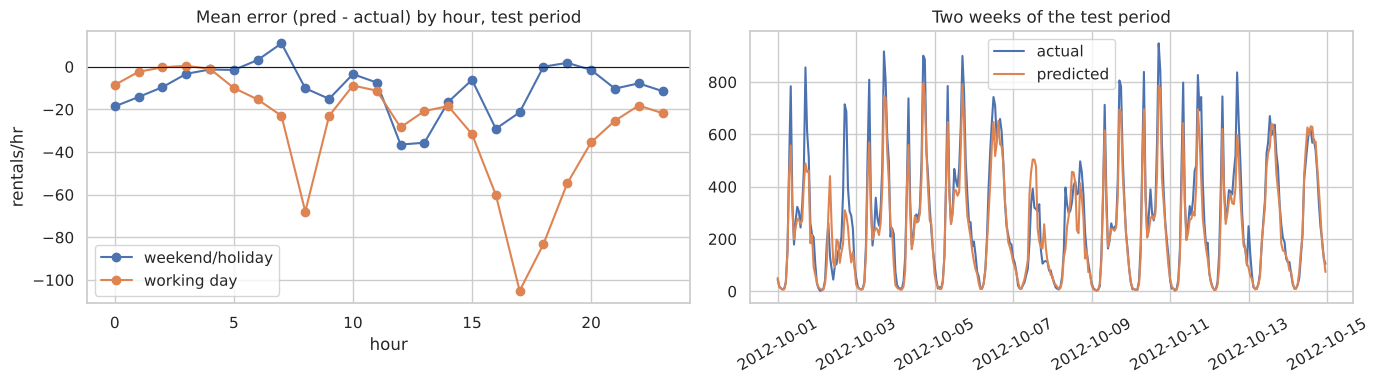

Mean error at working-day rush hours: -59.6 rentals/hr | overall: -22.4
Mean actual at rush hours: 540 | MAE at rush hours: 92.7


In [14]:
# Where does the model fail? Bias and error by hour, working days vs not
test["err"] = test.pred_hgb - test.cnt
bias = test.groupby(["workingday","hr"]).err.mean().unstack(0)
fig, ax = plt.subplots(1, 2, figsize=(14, 4))
bias.plot(ax=ax[0], marker="o"); ax[0].axhline(0, c="k", lw=.8)
ax[0].set(title="Mean error (pred - actual) by hour, test period", xlabel="hour", ylabel="rentals/hr"); ax[0].legend(["weekend/holiday","working day"])
s = test.sort_values("ts").query("ts >= '2012-10-01' and ts < '2012-10-15'")
ax[1].plot(s.ts, s.cnt, label="actual"); ax[1].plot(s.ts, s.pred_hgb, label="predicted")
ax[1].set(title="Two weeks of the test period"); ax[1].legend(); ax[1].tick_params(axis="x", rotation=30)
plt.tight_layout(); plt.show()
peak = test[test.is_rush==1]
print("Mean error at working-day rush hours: %.1f rentals/hr | overall: %.1f" % (peak.err.mean(), test.err.mean()))
print("Mean actual at rush hours: %.0f | MAE at rush hours: %.1f" % (peak.cnt.mean(), mean_absolute_error(peak.cnt, peak.pred_hgb)))

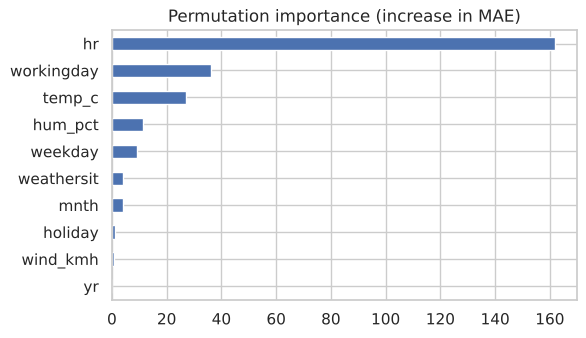

In [15]:
# Feature importance (permutation, on test data)
from sklearn.inspection import permutation_importance
pi = permutation_importance(hgb, test[feats], test.cnt, n_repeats=5, random_state=SEED, scoring="neg_mean_absolute_error")
pd.Series(pi.importances_mean, index=feats).sort_values().plot.barh(title="Permutation importance (increase in MAE)", figsize=(6,3.5)); plt.show()

## 6. Fleet estimate (lower-bound scenario, not a purchase number)

**Logic.** If R bikes are rented per hour and a trip lasts `TRIP_MIN` minutes, about `R x TRIP_MIN / 60` bikes are **in use** on average during that hour. Planning for the average hour would leave us short at busy times, so we use a high percentile of hourly demand.

**Assumptions to say out loud:** trip length is assumed (not in the data); rentals are not demand (unmet demand is invisible, so this is a floor); the percentile is a service-level choice; this is city-wide and says nothing about *where* bikes need to be.

In [16]:
def bikes_in_use(rentals_per_hr, trip_min=TRIP_MIN): return rentals_per_hr * trip_min / 60

obs  = test.cnt.values            # observed demand, test period
pred = test.pred_hgb.values       # model demand, test period

need_obs  = np.quantile(bikes_in_use(obs),  PCTL)
need_pred = np.quantile(bikes_in_use(pred), PCTL)
mean_use  = bikes_in_use(obs).mean()
print(f"Test period, trip = {TRIP_MIN} min, service level = P{int(PCTL*100)}")
print(f"  mean bikes in use (observed):      {mean_use:6.0f}")
print(f"  P{int(PCTL*100)} bikes in use (observed):     {need_obs:6.0f}")
print(f"  P{int(PCTL*100)} bikes in use (model forecast): {need_pred:6.0f}  (model under-predicts peaks, see section 5)")
print(f"  busiest single hour (observed):    {bikes_in_use(obs.max()):6.0f}")
print(f"  peak-to-average ratio (P{int(PCTL*100)} / mean): {need_obs/mean_use:.1f}x")
print(f"  => if the fleet were sized for P{int(PCTL*100)}, the average hour uses only {mean_use/need_obs:.0%} of it")

Test period, trip = 20 min, service level = P90
  mean bikes in use (observed):          85
  P90 bikes in use (observed):        192
  P90 bikes in use (model forecast):    175  (model under-predicts peaks, see section 5)
  busiest single hour (observed):       326
  peak-to-average ratio (P90 / mean): 2.3x
  => if the fleet were sized for P90, the average hour uses only 44% of it


Bikes in use (observed demand, test period)


,15 min,20 min,30 min,45 min
P50,54,71,107,160
P80,108,144,216,325
P90,144,192,289,433
P95,176,234,351,527
P99,216,289,433,649


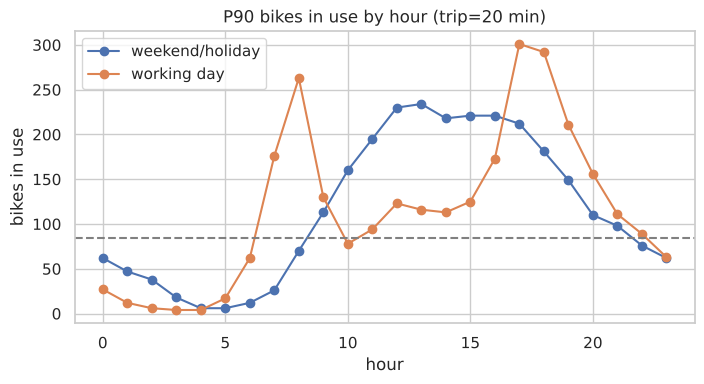

In [17]:
# Sensitivity: percentile x trip length (observed demand, test period, bikes in use)
pcts, trips = [0.5, 0.8, 0.9, 0.95, 0.99], [15, 20, 30, 45]
sens = pd.DataFrame({f"{t} min": [np.quantile(bikes_in_use(obs, t), p) for p in pcts] for t in trips},
                    index=[f"P{int(p*100)}" for p in pcts]).round(0).astype(int)
print("Bikes in use (observed demand, test period)"); display(sens)

# Time-of-day view: the real argument against 'buy more'
tod = (test.assign(need=bikes_in_use(test.cnt))
           .groupby(["workingday","hr"]).need.quantile(PCTL).unstack(0).round(0))
tod.columns = ["weekend/holiday","working day"]
ax = tod.plot(marker="o", figsize=(8,3.8), title=f"P{int(PCTL*100)} bikes in use by hour (trip={TRIP_MIN} min)")
ax.axhline(mean_use, ls="--", c="grey"); ax.set(xlabel="hour", ylabel="bikes in use"); plt.show()

In [18]:
# Extra buffers a real plan needs (all ASSUMPTIONS, shown as scenarios)
base = need_obs
rows = []
for maint in [0.05, 0.10, 0.15]:
    for spatial in [1.0, 1.5, 2.0]:
        rows.append({"maintenance share": maint, "spatial buffer x": spatial, "fleet": round(base/(1-maint)*spatial)})
display(pd.DataFrame(rows).pivot(index="maintenance share", columns="spatial buffer x", values="fleet"))

spatial buffer x,1.0,1.5,2.0
maintenance share,,,
0.05,203,304,405
0.10,214,321,428
0.15,226,340,453


## 7. Recommendation and limitations

**Answer to the CEO (draft, confirm with the printed numbers above):** do **not** buy bikes yet.
- Demand is highly concentrated. On working days the average hour has about 524 rentals at 5pm but about 5 at 3am. In the test period, bikes in use at the P90 hour (192 at a 20-minute trip) are about 2.3x the average hour (85), and the single busiest hour is about 3.8x. A fleet sized for P90 would be only about 44% used in an average hour. That fits "can't find a bike" and "bikes sit unused" being true at once.
- That pattern is *consistent with* a timing/distribution problem. It does **not prove** one: this data has no stations and no unmet demand.
- **Next steps:** (1) pilot forecast-guided rebalancing before commuter peaks in a few zones, using the experiment in section 4; (2) start logging failed searches / empty-station events and station-level availability; (3) check bike health (offline or broken bikes also look like "unused"); (4) revisit buying once those show shortages are system-wide.

| Limitation | Effect |
|---|---|
| Rentals are not demand | Fleet number is a floor |
| City-wide only | Cannot locate shortages |
| Trip length and buffers assumed | Fleet number moves with them (see sensitivity tables) |
| Weather used as recorded | Real forecast error would widen errors |
| Two years, strong growth | Yearly seasonality and trend are partly confounded |
| Boosting still under-predicts rush hours by about 60 rentals/hr on average (section 5), and the model variant was chosen after seeing test scores | Percentile sizing uses observed demand as the reference, not the forecast |